# BOLSTER's probe size and step size per epoch

BOLSTER drives SPSA on all weights with **one scalar Kalman filter** that is advanced once per epoch. Nothing in it is
tuned: the filter is initialised from the trained clean checkpoint $\theta_0$ and the epoch budget $E$ of the backprop
baseline (`SPSA_EPOCHS` in each sweep notebook):

$$P_0 = V\,\mathrm{RMS}(\theta_0),\qquad V = \mathrm{Var}_g\big(\mathrm{RMS}(\theta_{0,g})\big),\qquad R = E\,P_0,\qquad Q = 0,$$

where $g$ runs over the parameter-owning layers (conv / linear / batch-norm). Each epoch $e = 1 \dots E$:

$$P^-_e = P_{e-1} + Q,\qquad K_e = \frac{P^-_e}{P^-_e + R},\qquad c_e = P^-_e,\qquad a_e = K_e\,c_e,\qquad P_e = (1 - K_e)\,P^-_e,$$

and every SPSA step of that epoch uses the probe $c_e$ and the step coefficient $a_e$:
$\theta \leftarrow \theta - a_e\,\frac{L(\theta + c_e d) - L(\theta - c_e d)}{2 c_e}\,d$.
With $Q = 0$ the closed forms are $K_e = 1/(E+e)$, $c_e = P_0 E/(E+e-1)$ and $P_E = P_0/2$: the probe halves and the step
falls about four-fold over the run, at a scale that the checkpoint itself sets.

The gain $K_e = 1/(E+e)$ is the same for every benchmark up to $E$, so this notebook plots the two quantities that actually
enter the update, **the probe $c_e$ and the step coefficient $a_e$**, one panel per benchmark. Everything is recomputed
from the files of the sweeps: $P_0$ from each benchmark's clean checkpoint with the sweep notebooks' own rule, $E$ and $Q$
from the sweep notebook's configuration, and the schedule from the same recursion the runner uses.

In [ ]:
import re
from pathlib import PathF

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

/home/rahman2/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
FONT_FAMILY         = "DejaVu Sans"   # e.g. "serif", "Times New Roman", "Arial", ...
BASE_FONTSIZE       = 12              # default text size (titles, legend title, ...)
AXIS_LABEL_FONTSIZE = 13              # x/y axis label size
AXIS_TICK_FONTSIZE  = 11              # x/y tick label size
plt.rcParams.update({
    "font.family":     FONT_FAMILY,
    "font.size":       BASE_FONTSIZE,
    "axes.labelsize":  AXIS_LABEL_FONTSIZE,
    "axes.titlesize":  BASE_FONTSIZE + 1,
    "xtick.labelsize": AXIS_TICK_FONTSIZE,
    "ytick.labelsize": AXIS_TICK_FONTSIZE,
    "legend.fontsize": BASE_FONTSIZE - 3,
})

## Configuration

Only presentation choices and file locations live here. $P_0$, $E$ and $Q$ are read from each benchmark's files.

In [3]:
# Model folder -> panel title. The order here is the subplot order.
MODELS = {
    "lenet5_mnist":             "LeNet5/MNIST",
    "resnet20_cifar10":         "ResNet20/CIFAR10",
    "mobilenetv1_tinyimagenet": "MobileNet-v1/Tiny ImageNet",
}

CLEAN_CHECKPOINT   = "weights_baselines/full_retrain_var_0.0.pth"   # theta_0: the trained 0%-noise model (per model folder)
SWEEP_NOTEBOOK_GLOB = "bolster_noise_sweep*.ipynb"                   # the BOLSTER sweep notebook (per model folder)

# Overrides, keyed by model folder. Leave empty to take the values from the sweep notebooks' configuration cells.
EPOCHS_OVERRIDE = {}      # e.g. {"lenet5_mnist": 10}   (E = SPSA_EPOCHS)
Q_REL_OVERRIDE  = {}      # e.g. {"lenet5_mnist": 0.0}  (Q = KF_Q_REL * P0)

STEP_COLOR  = "#D62728"   # step coefficient a_e = K_e c_e   (left axis)
PROBE_COLOR = "#1F5FA8"   # probe c_e = P^-_e                 (right axis)

FIGSIZE     = (6.2, 4.2)
OUTPUT_DIR  = Path("figures")                      # one file per benchmark: bolster_kalman_schedule_<model folder>.png
OUTPUT_STEM = "bolster_kalman_schedule"

## The filter, as the sweep notebooks define it

`kf_init_from_state` reproduces `kf_init_from_checkpoint` of the sweeps: every module that owns parameters is one layer
(batch-norm running statistics are buffers, not parameters, and are excluded), $\mathrm{rms}_g$ is the RMS of that layer's
parameters, $V$ their population variance and $P_0 = V\,\mathrm{RMS}(\theta_0)$. `kf_plan` is the runner's `_kf_plan`.

In [4]:
_BUFFER_SUFFIXES = ("running_mean", "running_var", "num_batches_tracked")


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from `start` until a folder is found that contains the model folders."""
    for candidate in (start, *start.parents):
        if all((candidate / m).is_dir() for m in MODELS):
            return candidate
    raise FileNotFoundError(f"model folders {list(MODELS)} not found in {start} or its parents")


def kf_init_from_state(state: dict) -> dict:
    """V = Var_g(rms_g) over the parameter-owning layers, RMS = RMS(theta), P0 = V * RMS  (float64, as in the sweeps)."""
    layers = {}
    for key, value in state.items():
        if not torch.is_tensor(value) or not value.dtype.is_floating_point or key.endswith(_BUFFER_SUFFIXES):
            continue                                            # buffers (BN statistics) are not parameters
        layers.setdefault(key.rsplit(".", 1)[0], []).append(value.detach().to(torch.float64).reshape(-1))
    flat_g = [torch.cat(v) for v in layers.values()]
    rms_g  = torch.stack([torch.sqrt((t * t).mean()) for t in flat_g])
    theta  = torch.cat(flat_g)
    rms_all = torch.sqrt((theta * theta).mean())
    assert bool(torch.isfinite(rms_g).all()) and bool((rms_g > 0).all()), "a layer with all-zero or non-finite weights"
    V = rms_g.var(unbiased=False)                                 # population variance over the G layers
    return dict(V=float(V), rms_all=float(rms_all), P0=float(V * rms_all), G=len(layers), n_params=int(theta.numel()),
                rms_g=rms_g, layer_names=list(layers))


def kf_plan(P0: float, Q: float, R: float, epochs: int) -> dict:
    """The filter over `epochs` epochs: prior P^-, gain K, probe c = P^-, step a = K c, posterior P (per epoch)."""
    P = float(P0)
    rows = []
    for _ in range(int(epochs)):
        Pm = P + Q                     # predict
        K  = Pm / (Pm + R)             # gain  (H = 1)
        rows.append((Pm, K, Pm, K * Pm))
        P  = (1.0 - K) * Pm            # update
    arr = np.asarray(rows, dtype=np.float64)
    return dict(epoch=np.arange(1, int(epochs) + 1), P_prior=arr[:, 0], K=arr[:, 1], c=arr[:, 2], a=arr[:, 3],
                P_post=np.append(arr[1:, 0], P) - Q, P_end=P)


def _sweep_config_source(model_dir: Path) -> str:
    """The code of the BOLSTER sweep notebook of a model folder (its cells joined)."""
    import json
    nbs = sorted(model_dir.glob(SWEEP_NOTEBOOK_GLOB))
    if not nbs:
        raise FileNotFoundError(f"no {SWEEP_NOTEBOOK_GLOB} in {model_dir}")
    nb = json.loads(nbs[0].read_text())
    return "\n".join("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code")


def _config_int(src: str, name: str):
    """`name = <int>` in the source; `name = OTHER` is followed once (e.g. SPSA_EPOCHS = EPOCHS, EPOCHS, BATCH_SIZE = 10, 1024)."""
    m = re.search(rf"^\s*{name}\s*=\s*(\d+)\b", src, re.M)
    if m:
        return int(m.group(1))
    m = re.search(rf"^\s*{name}\s*=\s*([A-Z_]+)\s*(#|$)", src, re.M)
    if m:
        alias = m.group(1)
        m2 = re.search(rf"^\s*{alias}\s*(?:,\s*[A-Z_]+)*\s*=\s*(\d+)\b", src, re.M)
        if m2:
            return int(m2.group(1))
    return None


def _config_float(src: str, name: str):
    m = re.search(rf"^\s*{name}\s*=\s*([0-9.eE+-]+)\b", src, re.M)
    return float(m.group(1)) if m else None


def resolve_epochs(model_dir: Path) -> int:
    name = model_dir.name
    if name in EPOCHS_OVERRIDE:
        return int(EPOCHS_OVERRIDE[name])
    E = _config_int(_sweep_config_source(model_dir), "SPSA_EPOCHS")
    if E is None:
        raise ValueError(f"SPSA_EPOCHS not found in the sweep notebook of {name}; set EPOCHS_OVERRIDE[{name!r}]")
    return E


def resolve_q_rel(model_dir: Path) -> float:
    name = model_dir.name
    if name in Q_REL_OVERRIDE:
        return float(Q_REL_OVERRIDE[name])
    q = _config_float(_sweep_config_source(model_dir), "KF_Q_REL")
    return 0.0 if q is None else q

## Read the checkpoints and run the schedule

In [5]:
PROJECT_ROOT = find_project_root()
print(f"project root: {PROJECT_ROOT}\n")

runs = {}
for model_dir, title in MODELS.items():
    mdir = PROJECT_ROOT / model_dir
    ckpt = mdir / CLEAN_CHECKPOINT
    state = torch.load(ckpt, map_location="cpu", weights_only=False)
    kf0 = kf_init_from_state(state)
    E = resolve_epochs(mdir)
    q_rel = resolve_q_rel(mdir)
    P0, Q, R = kf0["P0"], q_rel * kf0["P0"], float(E) * kf0["P0"]
    plan = kf_plan(P0, Q, R, E)
    if Q == 0.0:   # closed forms hold with no process noise: K_e = 1/(E+e), c_e = P0 E/(E+e-1), P_E = P0/2
        e = plan["epoch"]
        assert np.allclose(plan["K"], 1.0 / (E + e)) and np.allclose(plan["c"], P0 * E / (E + e - 1))
        assert np.isclose(plan["P_end"], P0 / 2)
    runs[model_dir] = dict(title=title, kf0=kf0, E=E, Q=Q, R=R, plan=plan, ckpt=ckpt.relative_to(PROJECT_ROOT))
    print(f"== {title}   ({ckpt.relative_to(PROJECT_ROOT)})")
    print(f"   {kf0['n_params']:,} parameters in {kf0['G']} layers;  RMS(theta0) = {kf0['rms_all']:.4g},  "
          f"V = Var_g(rms_g) = {kf0['V']:.4g}  ->  P0 = V RMS = {P0:.4g}   (c_1/RMS = {P0 / kf0['rms_all']:.3%})")
    print(f"   E = {E} epochs,  R = E P0 = {R:.4g},  Q = {q_rel:g} P0 = {Q:.4g}")
    print(f"   epoch 1 -> {E}:  K {plan['K'][0]:.3e} -> {plan['K'][-1]:.3e};  c = P^- {plan['c'][0]:.3e} -> {plan['c'][-1]:.3e}  "
          f"(x{plan['c'][0] / plan['c'][-1]:.2f});  a = K c {plan['a'][0]:.3e} -> {plan['a'][-1]:.3e}  (x{plan['a'][0] / plan['a'][-1]:.2f});  "
          f"P ends at {plan['P_end'] / P0:.3f} P0\n")

project root: /home/rahman2/GIT/BOLSTER

== LeNet5/MNIST   (lenet5_mnist/weights_baselines/full_retrain_var_0.0.pth)
   61,706 parameters in 5 layers;  RMS(theta0) = 0.08744,  V = Var_g(rms_g) = 0.004555  ->  P0 = V RMS = 0.0003983   (c_1/RMS = 0.456%)
   E = 10 epochs,  R = E P0 = 0.003983,  Q = 0 P0 = 0
   epoch 1 -> 10:  K 9.091e-02 -> 5.000e-02;  c = P^- 3.983e-04 -> 2.096e-04  (x1.90);  a = K c 3.621e-05 -> 1.048e-05  (x3.45);  P ends at 0.500 P0

== ResNet20/CIFAR10   (resnet20_cifar10/weights_baselines/full_retrain_var_0.0.pth)
   272,282 parameters in 41 layers;  RMS(theta0) = 0.113,  V = Var_g(rms_g) = 0.07247  ->  P0 = V RMS = 0.008186   (c_1/RMS = 7.247%)
   E = 200 epochs,  R = E P0 = 1.637,  Q = 0 P0 = 0
   epoch 1 -> 200:  K 4.975e-03 -> 2.500e-03;  c = P^- 8.186e-03 -> 4.103e-03  (x1.99);  a = K c 4.073e-05 -> 1.026e-05  (x3.97);  P ends at 0.500 P0

== MobileNet-v1/Tiny ImageNet   (mobilenetv1_tinyimagenet/weights_baselines/full_retrain_var_0.0.pth)
   3,411,976 paramet

## Plot: probe $c_e$ and step coefficient $a_e$ per epoch, one figure per benchmark

saved /home/rahman2/GIT/BOLSTER/plots/figures/bolster_kalman_schedule_lenet5_mnist.png


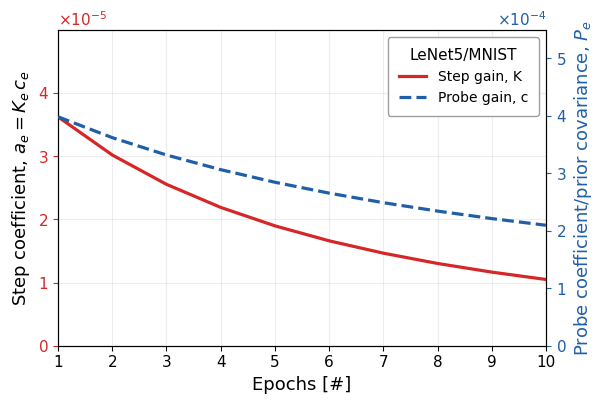

saved /home/rahman2/GIT/BOLSTER/plots/figures/bolster_kalman_schedule_resnet20_cifar10.png


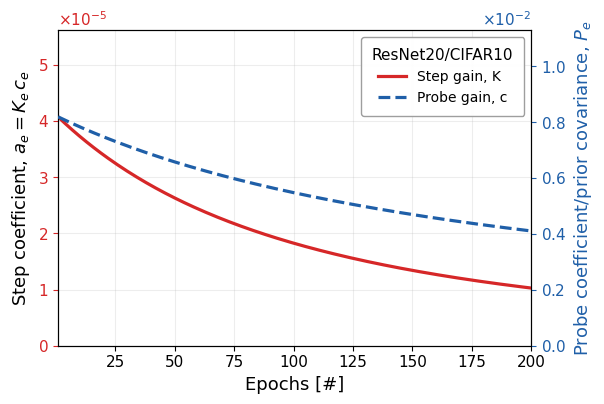

saved /home/rahman2/GIT/BOLSTER/plots/figures/bolster_kalman_schedule_mobilenetv1_tinyimagenet.png


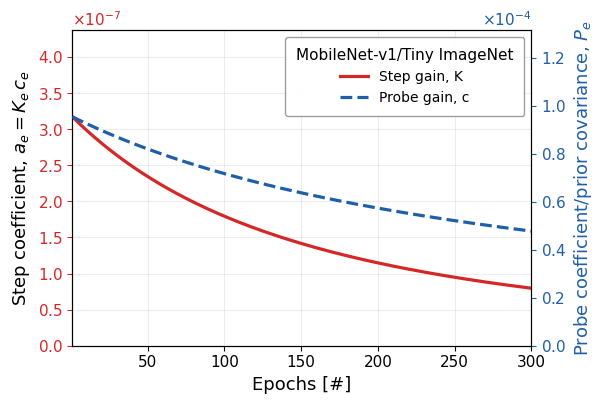

In [11]:
def _sci(ax_axis):
    fmt = ScalarFormatter(useMathText=True)
    fmt.set_powerlimits((-2, 2))
    ax_axis.set_major_formatter(fmt)


HEADROOM = 1.38      # y-range above the largest value: room for the value box
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for model_dir, r in runs.items():
    plan, E, P0, kf0 = r["plan"], r["E"], r["kf0"]["P0"], r["kf0"]
    e = plan["epoch"]
    marker = None

    fig, ax = plt.subplots(figsize=FIGSIZE)

    # ---- left axis: the step coefficient a_e = K_e c_e ----
    ax.plot(e, plan["a"], color=STEP_COLOR, lw=2.3, marker=marker, ms=5, zorder=4, label="Step gain, K")
    ax.set_ylim(0, HEADROOM * plan["a"].max())
    ax.set_xlim(1, E)
    ax.set_xlabel("Epochs [#]")
    ax.set_ylabel("Step coefficient, $a_e = K_e\\,c_e$")
    ax.tick_params(axis="y", colors=STEP_COLOR)
    _sci(ax.yaxis)
    ax.yaxis.get_offset_text().set_color(STEP_COLOR)
    ax.grid(True, alpha=0.22)

    # ---- right axis: the probe c_e = P^-_e (the prior covariance) ----
    ax2 = ax.twinx()
    ax2.plot(e, plan["c"], color=PROBE_COLOR, lw=2.3, ls="--", marker=marker, ms=5, zorder=3, label="Probe gain, c")
    ax2.set_ylim(0, HEADROOM * plan["c"].max())
    ax2.set_ylabel("Probe coefficient/prior covariance, $P_e$", color=PROBE_COLOR)
    ax2.tick_params(axis="y", colors=PROBE_COLOR)
    _sci(ax2.yaxis)
    ax2.yaxis.get_offset_text().set_color(PROBE_COLOR)

    # ---- the benchmark name, boxed in the upper-right corner (a text box pads evenly; a title-only legend does not) ----
    # ax.text(0.975, 0.965, r["title"], transform=ax.transAxes, fontsize=11, ha="right", va="top", zorder=6,
    #         bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.6", alpha=0.95))
    
    # ---- combined legend with benchmark name as title ----
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    legend = ax.legend(
        lines1 + lines2,
        labels1 + labels2,
        title=r["title"],
        loc="upper right",
        fontsize=10,
        title_fontsize=11,
        frameon=True,
        fancybox=True,
        framealpha=0.95,
        edgecolor="0.6",
        borderpad=0.8,
        labelspacing=0.5
    )

    legend.get_title()

    fig.tight_layout()
    out = OUTPUT_DIR / f"{OUTPUT_STEM}_{model_dir}.png"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    print(f"saved {out.resolve()}")
    plt.show()